In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
file_path = "../data/processed/gold_processed.csv"

df = pd.read_csv(file_path)

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,...,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,1200.099976,1200.099976,1221.199951,1197.699951,1198.199951,36,-0.001498,-0.001499,0.001586,...,1213.640000,0.037482,0.070568,0.095917,-0.006951,-0.019446,-0.045570,196.80,0.182927,0.131764
1,2017-03-16,1226.500000,1226.500000,1231.400024,1222.199951,1222.199951,47,0.021998,0.021760,0.003518,...,1214.962000,0.158972,0.131803,0.123242,0.020043,-0.004222,-0.024575,190.40,0.246849,0.068388
2,2017-03-17,1229.800049,1229.800049,1230.900024,1227.099976,1227.099976,26,0.002691,0.002687,0.002200,...,1216.282000,0.152766,0.129747,0.121049,0.024236,-0.008226,-0.021950,187.35,0.138778,0.070286
3,2017-03-20,1233.599976,1233.599976,1234.400024,1229.300049,1229.300049,23,0.003090,0.003085,0.003498,...,1217.360000,0.150890,0.130242,0.121522,0.025948,-0.003232,-0.018928,173.45,0.132603,0.073056
4,2017-03-21,1246.099976,1246.099976,1246.099976,1226.400024,1226.400024,11,0.010133,0.010082,0.016063,...,1218.843999,0.144897,0.128541,0.126849,0.036775,0.006949,-0.008987,168.05,0.065457,0.046028


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

Shape: (2380, 24)

Columns:
['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'volume_ma_20', 'volume_ratio', 'target_5d_volatility']

Missing Values:
0


In [4]:
features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5",
    "volatility_10",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "drawdown"
]

features = [
    col for col in features
    if col in df.columns
]

target = "target_5d_volatility"

print("Features:")
print(features)

print("\nTarget:", target)

Features:
['daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'drawdown']

Target: target_5d_volatility


In [5]:
model_df = df[
    ["date"] + features + [target]
].copy()

model_df = model_df.dropna()

model_df = model_df.sort_values(
    "date"
).reset_index(drop=True)

print("Model Dataset Shape:", model_df.shape)

model_df.head()

Model Dataset Shape: (2380, 11)


,date,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,drawdown,target_5d_volatility
0,2017-03-15,-0.001498,-0.001499,0.001586,0.019582,1201.500000,1211.300000,1227.889996,1213.640000,-0.045570,0.131764
1,2017-03-16,0.021998,0.021760,0.003518,0.007501,1206.319995,1210.759998,1227.629999,1214.962000,-0.024575,0.068388
2,2017-03-17,0.002691,0.002687,0.002200,0.003090,1212.140015,1211.190002,1227.120001,1216.282000,-0.021950,0.070286
3,2017-03-20,0.003090,0.003085,0.003498,0.004134,1218.380005,1212.100000,1226.920001,1217.360000,-0.018928,0.073056
4,2017-03-21,0.010133,0.010082,0.016063,0.015809,1227.219995,1215.200000,1227.350000,1218.843999,-0.008987,0.046028


In [6]:
print(model_df[target].describe())

count    2380.000000
mean        0.144473
std         0.092713
min         0.018791
25%         0.086219
50%         0.122781
75%         0.178254
max         1.122901
Name: target_5d_volatility, dtype: float64


In [7]:
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training Rows:", len(train_df))
print("Testing Rows:", len(test_df))

Training Rows: 1904
Testing Rows: 476


In [8]:
print("Training Date Range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting Date Range:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training Date Range:
2017-03-15 00:00:00 to 2024-10-08 00:00:00

Testing Date Range:
2024-10-09 00:00:00 to 2026-08-31 00:00:00


In [9]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1904, 9)
X_test: (476, 9)


In [10]:
baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.10169437946681378
Baseline RMSE: 0.15796145794756092


In [11]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 0.08025321437553223
Linear Regression RMSE: 0.11803820588631989


In [12]:
coefficients = pd.DataFrame({
    "feature": features,
    "coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    by="coefficient",
    key=abs,
    ascending=False
)

coefficients

,feature,coefficient
1,log_return,4.482191
0,daily_return,-4.153995
3,price_range,2.513373
8,drawdown,-0.148247
2,intraday_return,0.072765
5,ma_10,0.000299
7,ma_50,-0.000198
6,ma_20,-0.000067
4,ma_5,-0.000004


In [13]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.09790606323999897
Random Forest RMSE: 0.15247103883405871


In [14]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

results

,Model,MAE,RMSE
0,Baseline,0.101694,0.157961
1,Linear Regression,0.080253,0.118038
2,Random Forest,0.097906,0.152471


In [15]:
results_path = "../data/processed/gold_initial_model_results.csv"

results.to_csv(
    results_path,
    index=False
)

print("Model results saved successfully!")
print(results_path)

Model results saved successfully!
../data/processed/gold_initial_model_results.csv


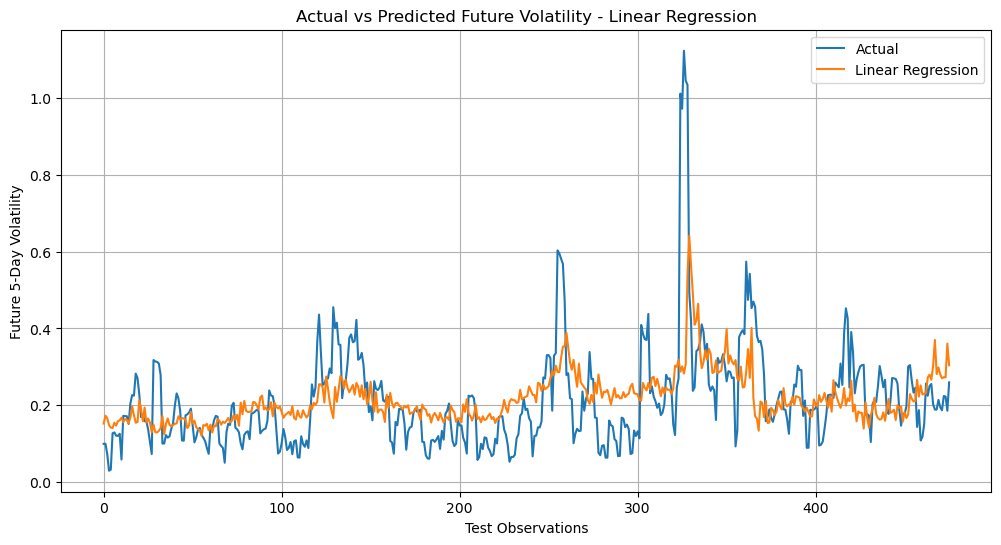

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    linear_predictions,
    label="Linear Regression"
)

plt.title("Actual vs Predicted Future Volatility - Linear Regression")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

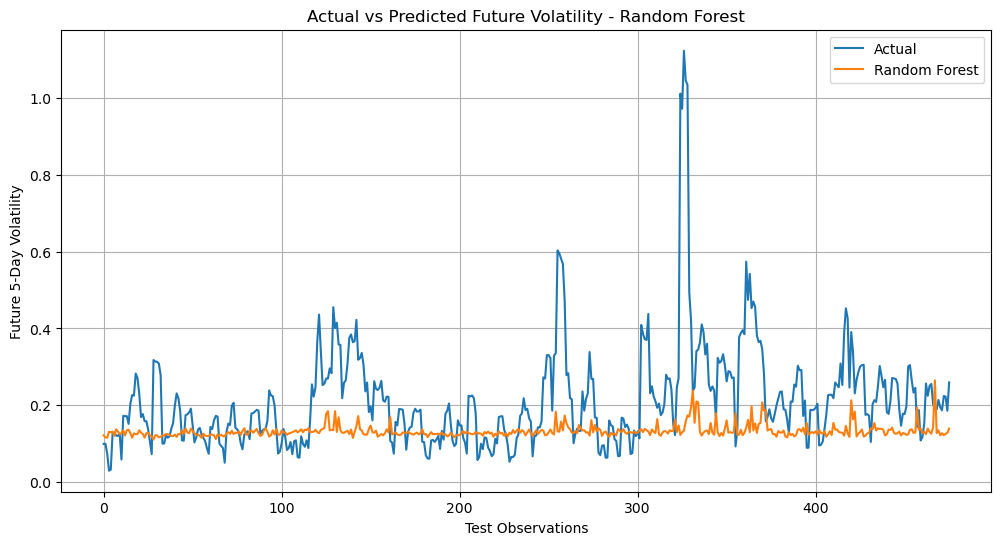

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    rf_predictions,
    label="Random Forest"
)

plt.title("Actual vs Predicted Future Volatility - Random Forest")
plt.xlabel("Test Observations")
plt.ylabel("Future 5-Day Volatility")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
7,ma_50,0.262809
5,ma_10,0.149700
6,ma_20,0.143018
4,ma_5,0.130220
3,price_range,0.116449
8,drawdown,0.089465
2,intraday_return,0.048164
1,log_return,0.030174
0,daily_return,0.030002


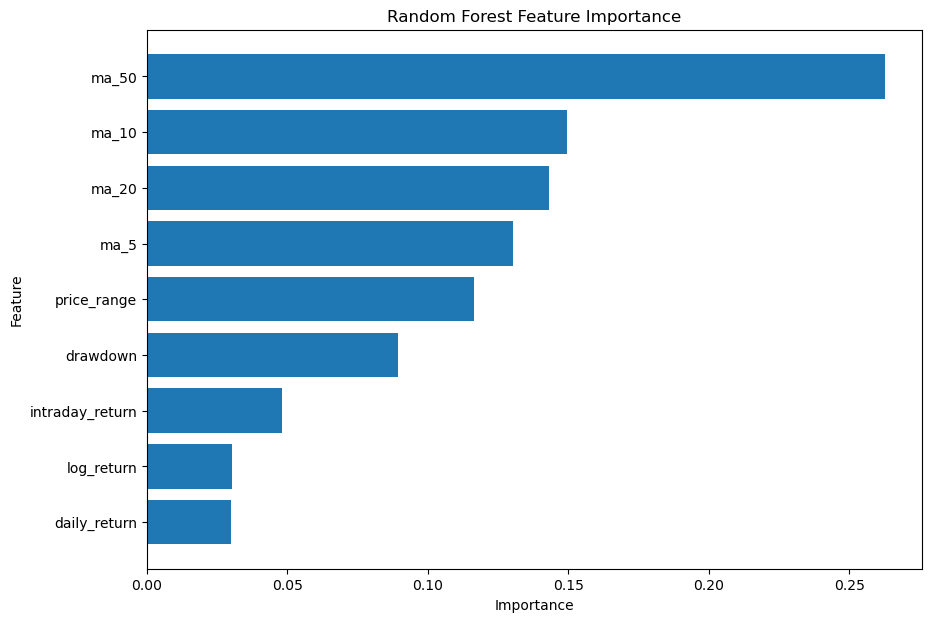

In [19]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [20]:
importance_path = "../data/processed/gold_random_forest_feature_importance.csv"

feature_importance.to_csv(
    importance_path,
    index=False
)

print("Feature importance saved successfully!")
print(importance_path)

Feature importance saved successfully!
../data/processed/gold_random_forest_feature_importance.csv


In [21]:
prediction_df = pd.DataFrame({
    "date": test_df["date"].values,
    "actual": y_test.values,
    "linear_regression": linear_predictions,
    "random_forest": rf_predictions
})

prediction_df.head(20)

,date,actual,linear_regression,random_forest
0,2024-10-09,0.099541,0.152466,0.121920
1,2024-10-10,0.099890,0.172766,0.116030
2,2024-10-11,0.073459,0.166487,0.115831
3,2024-10-14,0.029665,0.148410,0.131036
4,2024-10-15,0.032571,0.142032,0.129991
5,2024-10-16,0.127121,0.140712,0.131302
6,2024-10-17,0.129344,0.154539,0.120407
7,2024-10-18,0.120967,0.147223,0.137374
8,2024-10-21,0.120438,0.158541,0.131956
9,2024-10-22,0.125844,0.161007,0.124617


In [22]:
prediction_path = "../data/processed/gold_model_predictions.csv"

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("Predictions saved successfully!")
print(prediction_path)

Predictions saved successfully!
../data/processed/gold_model_predictions.csv


In [23]:
print("GOLD INITIAL MODEL EXPERIMENT")
print("----------------------------")

print("\nTarget:")
print(target)

print("\nModels Tested:")
print("1. Baseline")
print("2. Linear Regression")
print("3. Random Forest")

print("\nEvaluation Metrics:")
print("1. MAE")
print("2. RMSE")

print("\nTraining Rows:", len(train_df))
print("Testing Rows:", len(test_df))

print("\nModel Results:")
print(results)

GOLD INITIAL MODEL EXPERIMENT
----------------------------

Target:
target_5d_volatility

Models Tested:
1. Baseline
2. Linear Regression
3. Random Forest

Evaluation Metrics:
1. MAE
2. RMSE

Training Rows: 1904
Testing Rows: 476

Model Results:
               Model       MAE      RMSE
0           Baseline  0.101694  0.157961
1  Linear Regression  0.080253  0.118038
2      Random Forest  0.097906  0.152471
